In [3]:
#GPU T4*2
!nvidia-smi -L

GPU 0: Tesla T4 (UUID: GPU-5f4db38e-c89d-07a0-c3b2-f56765dca7de)
GPU 1: Tesla T4 (UUID: GPU-e9a8d67d-792f-92f3-3f5d-cdade75dcc18)


In [5]:
#PHB
!nvidia-smi topo -m

	GPU0	GPU1	CPU Affinity	NUMA Affinity	GPU NUMA ID
GPU0	 X 	PHB	0-3	0		N/A
GPU1	PHB	 X 	0-3	0		N/A

Legend:

  X    = Self
  SYS  = Connection traversing PCIe as well as the SMP interconnect between NUMA nodes (e.g., QPI/UPI)
  NODE = Connection traversing PCIe as well as the interconnect between PCIe Host Bridges within a NUMA node
  PHB  = Connection traversing PCIe as well as a PCIe Host Bridge (typically the CPU)
  PXB  = Connection traversing multiple PCIe bridges (without traversing the PCIe Host Bridge)
  PIX  = Connection traversing at most a single PCIe bridge
  NV#  = Connection traversing a bonded set of # NVLinks


In [2]:
#instal nccl-tests
!apt-get update -qq && apt-get install -y -qq libnccl2 libnccl-dev 2>&1 | tail -2
!git clone --depth 1 https://github.com/NVIDIA/nccl-tests.git
!cd nccl-tests && make -j$(nproc) 2>&1 | tail -3
!ls nccl-tests/build/all_reduce_perf

W: https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2404/x86_64/InRelease: Key is stored in legacy trusted.gpg keyring (/etc/apt/trusted.gpg), see the DEPRECATION section in apt-key(8) for details.
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
E: Held packages were changed and -y was used without --allow-change-held-packages.
Cloning into 'nccl-tests'...
remote: Enumerating objects: 91, done.
remote: Counting objects: 100% (91/91), done.
remote: Compressing objects: 100% (77/77), done.
remote: Total 91 (delta 29), reused 41 (delta 12), pack-reused 0 (from 0)
Receiving objects: 100% (91/91), 129.82 KiB | 2.40 MiB/s, done.
Resolving deltas: 100% (29/29), done.
nvcc warning : Support for offline compilation for architectures prior to '<compute/sm/lto>_75' will be removed in a future release (Use -Wno-deprecated-gpu-targets to suppress

In [6]:
#run all redeuce perf
!cd nccl-tests && NCCL_DEBUG=INFO NCCL_DEBUG_SUBSYS=INIT,TUNING,COLL ./build/all_reduce_perf -b 1K -e 256M -f 8 -g 2 -n 1 -w 1 2>&1 | tee saturday_diag.log


# nccl-tests version 2.21.1 (afd59ab) nccl-headers=22501 nccl-library=22501
# Collective test starting: all_reduce_perf
# nThread 1 nGpus 2 minBytes 1024 maxBytes 268435456 step: 8(factor) warmup iters: 1 iters: 1 agg iters: 1 validation: 1 graph: 0 unalign: 0
#
# Using devices
#  Rank  0 Group  0 Pid   2276 on 610da0310437 device  0 [0000:00:04] Tesla T4
#  Rank  1 Group  0 Pid   2276 on 610da0310437 device  1 [0000:00:05] Tesla T4
610da0310437:2276:2276 [0] NCCL INFO cudaDriverVersion 13000
610da0310437:2276:2276 [0] NCCL INFO NCCL version 2.25.1+cuda12.8
610da0310437:2276:2282 [0] NCCL INFO NET/Plugin: Could not find: libnccl-net.so. Using internal network plugin.
610da0310437:2276:2282 [0] NCCL INFO NET/IB : No device found.
610da0310437:2276:2282 [0] NCCL INFO NET/IB : Using [RO]; OOB eth0:172.19.2.2<0>
610da0310437:2276:2282 [0] NCCL INFO NET/Socket : Using [0]eth0:172.19.2.2<0>
610da0310437:2276:2282 [0] NCCL INFO Using network Socket
610da0310437:2276:2283 [1] NCCL INFO Using n

In [7]:
#check bytes for logs
!grep "Bytes ->" nccl-tests/saturday_diag.log

610da0310437:2276:2276 [0] NCCL INFO AllReduce: 1024 Bytes -> Algo RING proto LL channel{Lo..Hi}={0..0}
610da0310437:2276:2276 [0] NCCL INFO AllReduce: 1024 Bytes -> Algo RING proto LL channel{Lo..Hi}={0..0}
610da0310437:2276:2276 [0] NCCL INFO AllReduce: 1024 Bytes -> Algo RING proto LL channel{Lo..Hi}={0..0}
610da0310437:2276:2276 [0] NCCL INFO AllReduce: 1024 Bytes -> Algo RING proto LL channel{Lo..Hi}={0..0}
610da0310437:2276:2276 [0] NCCL INFO AllReduce: 1024 Bytes -> Algo RING proto LL channel{Lo..Hi}={0..0}
610da0310437:2276:2276 [0] NCCL INFO AllReduce: 1024 Bytes -> Algo RING proto LL channel{Lo..Hi}={0..0}
610da0310437:2276:2276 [0] NCCL INFO AllReduce: 8192 Bytes -> Algo RING proto LL channel{Lo..Hi}={0..0}
610da0310437:2276:2276 [0] NCCL INFO AllReduce: 8192 Bytes -> Algo RING proto LL channel{Lo..Hi}={0..0}
610da0310437:2276:2276 [0] NCCL INFO AllReduce: 8192 Bytes -> Algo RING proto LL channel{Lo..Hi}={0..0}
610da0310437:2276:2276 [0] NCCL INFO AllReduce: 8192 Bytes -> Al

In [8]:
#three times
!cd nccl-tests && for i in 1 2 3; do ./build/all_reduce_perf -b 8 -e 512M -f 2 -g 2 2>&1 | tee baseline_$i.log; done

# nccl-tests version 2.21.1 (afd59ab) nccl-headers=22501 nccl-library=22501
# Collective test starting: all_reduce_perf
# nThread 1 nGpus 2 minBytes 8 maxBytes 536870912 step: 2(factor) warmup iters: 1 iters: 20 agg iters: 1 validation: 1 graph: 0 unalign: 0
#
# Using devices
#  Rank  0 Group  0 Pid   2308 on 610da0310437 device  0 [0000:00:04] Tesla T4
#  Rank  1 Group  0 Pid   2308 on 610da0310437 device  1 [0000:00:05] Tesla T4
#
#                                                              out-of-place                       in-place
#       size         count      type   redop    root     time   algbw   busbw  #wrong     time   algbw   busbw  #wrong
#        (B)    (elements)                               (us)  (GB/s)  (GB/s)             (us)  (GB/s)  (GB/s)        
           8             2     float     sum      -1    17.81    0.00    0.00       0    15.53    0.00    0.00       0
          16             4     float     sum      -1    15.57    0.00    0.00       0    15.22    0

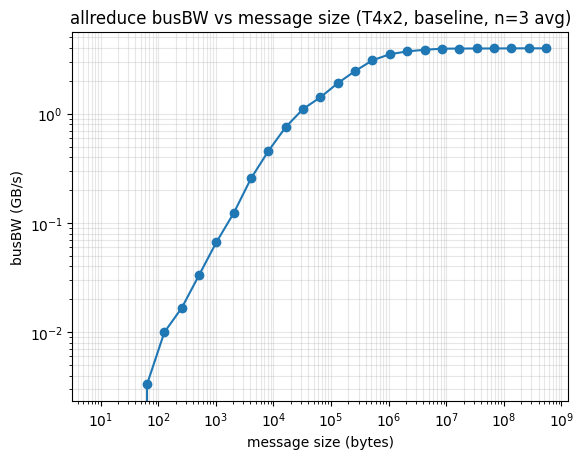

alpha = 15.4 us, beta = 4.0 GB/s, 拐点 ≈ 0.06 MB


In [9]:
# draw line
import matplotlib.pyplot as plt
import numpy as np

def parse(path):
    d = {}
    for line in open(path):
        c = line.split()
        if len(c) >= 8 and c[0].isdigit():
            d[int(c[0])] = (float(c[5]), float(c[7]))
    return d

def avg(paths):
    ds = [parse(p) for p in paths]
    common = set(ds[0])
    for d in ds[1:]:
        common &= set(d)
    out = {}
    for s in sorted(common):
        out[s] = (sum(d[s][0] for d in ds)/len(ds),
                  sum(d[s][1] for d in ds)/len(ds))
    return out

base = avg(['nccl-tests/baseline_1.log','nccl-tests/baseline_2.log','nccl-tests/baseline_3.log'])
xs = sorted(base); ys = [base[s][1] for s in xs]

plt.figure()
plt.xscale('log'); plt.yscale('log')
plt.plot(xs, ys, marker='o')
plt.xlabel('message size (bytes)'); plt.ylabel('busBW (GB/s)')
plt.title('allreduce busBW vs message size (T4x2, baseline, n=3 avg)')
plt.grid(True, which='both', alpha=0.3)
plt.savefig('saturday_busbw.png'); plt.show()

# α-β 两段拟合
xs_arr = np.array(xs, dtype=float)
ts = np.array([base[s][0] for s in xs])
mask_big = xs_arr >= 2**20
k, _ = np.polyfit(xs_arr[mask_big], ts[mask_big], 1)
beta_gbps = 1e-3 / k
mask_small = xs_arr <= 2**10
alpha = ts[mask_small].mean()
knee = alpha / k
print(f"alpha = {alpha:.1f} us, beta = {beta_gbps:.1f} GB/s, 拐点 ≈ {knee/2**20:.2f} MB")


In [10]:
#tree vs ring
!cd nccl-tests && NCCL_ALGO=Tree NCCL_DEBUG=INFO NCCL_DEBUG_SUBSYS=INIT,TUNING,COLL ./build/all_reduce_perf -b 1M -e 1M -g 2 -n 1 -w 1 2>&1 | tee tree_diag.log
!grep "Bytes ->" nccl-tests/tree_diag.log | head -3
!cd nccl-tests && for i in 1 2 3; do NCCL_ALGO=Tree ./build/all_reduce_perf -b 8 -e 512M -f 2 -g 2 2>&1 | tee tree_$i.log; done
!cd nccl-tests && for i in 1 2 3; do NCCL_ALGO=Ring ./build/all_reduce_perf -b 8 -e 512M -f 2 -g 2 2>&1 | tee ring_$i.log; done


# nccl-tests version 2.21.1 (afd59ab) nccl-headers=22501 nccl-library=22501
# Collective test starting: all_reduce_perf
# nThread 1 nGpus 2 minBytes 1048576 maxBytes 1048576 step: 1048576(bytes) warmup iters: 1 iters: 1 agg iters: 1 validation: 1 graph: 0 unalign: 0
#
# Using devices
#  Rank  0 Group  0 Pid   2388 on 610da0310437 device  0 [0000:00:04] Tesla T4
#  Rank  1 Group  0 Pid   2388 on 610da0310437 device  1 [0000:00:05] Tesla T4
610da0310437:2388:2388 [0] NCCL INFO cudaDriverVersion 13000
610da0310437:2388:2388 [0] NCCL INFO NCCL version 2.25.1+cuda12.8
610da0310437:2388:2394 [0] NCCL INFO NET/Plugin: Could not find: libnccl-net.so. Using internal network plugin.
610da0310437:2388:2394 [0] NCCL INFO NET/IB : No device found.
610da0310437:2388:2394 [0] NCCL INFO NET/IB : Using [RO]; OOB eth0:172.19.2.2<0>
610da0310437:2388:2394 [0] NCCL INFO NET/Socket : Using [0]eth0:172.19.2.2<0>
610da0310437:2388:2394 [0] NCCL INFO Using network Socket
610da0310437:2388:2395 [1] NCCL INFO U

In [11]:
#SHM
!cd nccl-tests && NCCL_SHM_DISABLE=1 NCCL_DEBUG=INFO NCCL_DEBUG_SUBSYS=INIT,TUNING,COLL ./build/all_reduce_perf -b 1M -e 1M -g 2 -n 1 -w 1 2>&1 | tee noshm_diag.log
!grep " via " nccl-tests/noshm_diag.log | head
!cd nccl-tests && for i in 1 2 3; do NCCL_SHM_DISABLE=1 ./build/all_reduce_perf -b 8 -e 512M -f 2 -g 2 2>&1 | tee noshm_$i.log; done


# nccl-tests version 2.21.1 (afd59ab) nccl-headers=22501 nccl-library=22501
# Collective test starting: all_reduce_perf
# nThread 1 nGpus 2 minBytes 1048576 maxBytes 1048576 step: 1048576(bytes) warmup iters: 1 iters: 1 agg iters: 1 validation: 1 graph: 0 unalign: 0
#
# Using devices
#  Rank  0 Group  0 Pid   2539 on 610da0310437 device  0 [0000:00:04] Tesla T4
#  Rank  1 Group  0 Pid   2539 on 610da0310437 device  1 [0000:00:05] Tesla T4
610da0310437:2539:2539 [0] NCCL INFO cudaDriverVersion 13000
610da0310437:2539:2539 [0] NCCL INFO NCCL version 2.25.1+cuda12.8
610da0310437:2539:2545 [0] NCCL INFO NET/Plugin: Could not find: libnccl-net.so. Using internal network plugin.
610da0310437:2539:2545 [0] NCCL INFO NET/IB : No device found.
610da0310437:2539:2545 [0] NCCL INFO NET/IB : Using [RO]; OOB eth0:172.19.2.2<0>
610da0310437:2539:2545 [0] NCCL INFO NET/Socket : Using [0]eth0:172.19.2.2<0>
610da0310437:2539:2545 [0] NCCL INFO Using network Socket
610da0310437:2539:2546 [1] NCCL INFO U

skip no-p2p


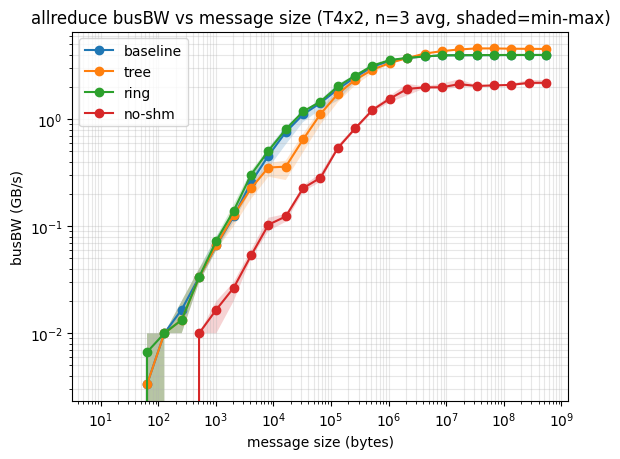

In [12]:
#multi graph
def minmax(paths):
    ds = [parse(p) for p in paths]
    common = set(ds[0])
    for d in ds[1:]: common &= set(d)
    out = {}
    for s in sorted(common):
        bs = [d[s][1] for d in ds]
        out[s] = (sum(bs)/len(bs), min(bs), max(bs))
    return out

conds = {
    'baseline': ['nccl-tests/baseline_1.log','nccl-tests/baseline_2.log','nccl-tests/baseline_3.log'],
    'tree':     ['nccl-tests/tree_1.log','nccl-tests/tree_2.log','nccl-tests/tree_3.log'],
    'ring':     ['nccl-tests/ring_1.log','nccl-tests/ring_2.log','nccl-tests/ring_3.log'],
    'no-p2p':   ['nccl-tests/nop2p_1.log','nccl-tests/nop2p_2.log','nccl-tests/nop2p_3.log'],
    'no-shm':   ['nccl-tests/noshm_1.log','nccl-tests/noshm_2.log','nccl-tests/noshm_3.log'],
}
plt.figure()
for name, paths in conds.items():
    try:
        a = minmax(paths)
        srt = sorted(a)
        mean = [a[s][0] for s in srt]; lo = [a[s][1] for s in srt]; hi = [a[s][2] for s in srt]
        plt.plot(srt, mean, marker='o', label=name)
        plt.fill_between(srt, lo, hi, alpha=0.2)
    except FileNotFoundError:
        print(f"skip {name}")
plt.xscale('log'); plt.yscale('log')
plt.xlabel('message size (bytes)'); plt.ylabel('busBW (GB/s)')
plt.title('allreduce busBW vs message size (T4x2, n=3 avg, shaded=min-max)')
plt.legend(); plt.grid(True, which='both', alpha=0.3)
plt.savefig('saturday_compare.png'); plt.show()


In [17]:
#ring 512
!cd nccl-tests && NCCL_ALGO=Ring NCCL_NTHREADS=512 NCCL_DEBUG=INFO NCCL_DEBUG_SUBSYS=INIT,ENV,TUNING ./build/all_reduce_perf -b 1M -e 1M -g 2 -n 1 -w 1 2>&1 | tee ring512_diag.log
!grep -E "NTHREADS|Max NThreads|Bytes ->" nccl-tests/ring512_diag.log | head

# nccl-tests version 2.21.1 (afd59ab) nccl-headers=22501 nccl-library=22501
# Collective test starting: all_reduce_perf
# nThread 1 nGpus 2 minBytes 1048576 maxBytes 1048576 step: 1048576(bytes) warmup iters: 1 iters: 1 agg iters: 1 validation: 1 graph: 0 unalign: 0
#
# Using devices
#  Rank  0 Group  0 Pid   2661 on 610da0310437 device  0 [0000:00:04] Tesla T4
#  Rank  1 Group  0 Pid   2661 on 610da0310437 device  1 [0000:00:05] Tesla T4
610da0310437:2661:2661 [0] NCCL INFO cudaDriverVersion 13000
610da0310437:2661:2661 [0] NCCL INFO NCCL version 2.25.1+cuda12.8
610da0310437:2661:2668 [0] NCCL INFO NET/Plugin: Could not find: libnccl-net.so. Using internal network plugin.
610da0310437:2661:2668 [0] NCCL INFO NET/IB : No device found.
610da0310437:2661:2668 [0] NCCL INFO NET/IB : Using [RO]; OOB eth0:172.19.2.2<0>
610da0310437:2661:2668 [0] NCCL INFO NET/Socket : Using [0]eth0:172.19.2.2<0>
610da0310437:2661:2668 [0] NCCL INFO PROFILER/Plugin: Could not find: libnccl-profiler.so.
610da

In [18]:
#ring256
!cd nccl-tests && for i in 1 2 3; do NCCL_ALGO=Tree NCCL_NTHREADS=256 ./build/all_reduce_perf -b 8 -e 512M -f 2 -g 2 2>&1 | tee tree256_$i.log; done

# nccl-tests version 2.21.1 (afd59ab) nccl-headers=22501 nccl-library=22501
# Collective test starting: all_reduce_perf
# nThread 1 nGpus 2 minBytes 8 maxBytes 536870912 step: 2(factor) warmup iters: 1 iters: 20 agg iters: 1 validation: 1 graph: 0 unalign: 0
#
# Using devices
#  Rank  0 Group  0 Pid   2700 on 610da0310437 device  0 [0000:00:04] Tesla T4
#  Rank  1 Group  0 Pid   2700 on 610da0310437 device  1 [0000:00:05] Tesla T4
#
#                                                              out-of-place                       in-place
#       size         count      type   redop    root     time   algbw   busbw  #wrong     time   algbw   busbw  #wrong
#        (B)    (elements)                               (us)  (GB/s)  (GB/s)             (us)  (GB/s)  (GB/s)        
           8             2     float     sum      -1    20.84    0.00    0.00       0    18.69    0.00    0.00       0
          16             4     float     sum      -1    18.76    0.00    0.00       0    19.79    0